In [1]:
import pickle
import pathlib

import numpy as np
import pandas as pd
import matplotlib as mlp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from models.EEGNet import EEGNet, ConstrainedConv2d, ConstrainedLinear
from models.GATGRU import MultiBranchGATGRUTransformer, SpatialBranch, FrequencyBranch, TemporalBranch, GATLayer

RESULTS_DIR = pathlib.Path('out/results')

def load_cached(name: str):
    cache_path = RESULTS_DIR / f"{name}.pkl"

    with open(cache_path, "rb") as fh:
        cached = pickle.load(fh)
        return cached["result"]

rf_general_run, rf_general_run_meta = load_cached('rf_general_run')
rf_cross_session_run, rf_cross_session_run_meta = load_cached('rf_cross_session_run')
rf_leave_one_out_run = load_cached('rf_leave_one_out_run')
rf_leave_one_out_gaze_run = load_cached('rf_leave_one_out_gaze_run')
rf_leave_one_out_hinted_run = load_cached('rf_leave_one_out_hinted_run')
rf_leave_one_out_finger_run = load_cached('rf_leave_one_out_finger_run')
rf_leave_one_out_augmented_run = load_cached('rf_leave_one_out_augmented_run')
rf_robust_general_run, rf_robust_general_run_meta = load_cached('rf_robust_general_run')
rf_robust_leave_one_out_run = load_cached('rf_robust_leave_one_out_run')

eegnet_general_run, eegnet_general_run_meta = load_cached('eegnet_general_run')
eegnet_cross_session_run, eegnet_cross_session_run_meta = load_cached('eegnet_cross_session_run')
eegnet_leave_one_out_run = load_cached('eegnet_leave_one_out_run')
eegnet_leave_one_out_gaze_run = load_cached('eegnet_leave_one_out_gaze_run')
eegnet_leave_one_out_hinted_run = load_cached('eegnet_leave_one_out_hinted_run')
eegnet_leave_one_out_ignored_run = load_cached('eegnet_leave_one_out_ignored_run')
eegnet_leave_one_out_augmented_run = load_cached('eegnet_leave_one_out_ignored_run')
eegnet_leave_one_out_finger_run = load_cached('eegnet_leave_one_out_finger_run')
eegnet_robust_general_run, eegnet_general_run_meta = load_cached('eegnet_robust_general_run')
eegnet_robust_leave_one_out_run = load_cached('eegnet_robust_leave_one_out_run')

transformer_general_run = load_cached('transformer_general_run')
transformer_cross_session_run, transformer_cross_session_run_meta = load_cached('transformer_cross_session_run')
transformer_leave_one_out_run = load_cached('transformer_leave_one_out_run')
transformer_leave_one_out_gaze_run = load_cached('transformer_leave_one_out_gaze_run')
transformer_leave_one_out_hinted_run = load_cached('transformer_leave_one_out_hinted_run')
transformer_leave_one_out_ignored_run = load_cached('transformer_leave_one_out_ignored_run')
transformer_leave_one_out_augmented_run = load_cached('transformer_leave_one_out_augmented_run')
transformer_leave_one_out_finger_run = load_cached('transformer_leave_one_out_finger_run')
transformer_robust_general_run = load_cached('transformer_robust_general_run')
transformer_robust_leave_one_out_run = load_cached('transformer_robust_leave_one_out_run')

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


# Results analysis

In [2]:
from scripts.paper_style import (TEXT_W, COL_W, CAT_COLORS, SEQ_CMAP, DIV_CMAP, INK_PRIMARY, INK_SECONDARY,
                         GRID_COLOR, SPINE_COLOR, clean_axes, enforce_font_sizes, subject_id)

OUT_DIR = pathlib.Path('out/figs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    enforce_font_sizes(fig)
    path = OUT_DIR / name
    fig.savefig(path)
    print('wrote', path)

wrote out_thesis\figs\pub\model_perf_by_dataset_split.pdf


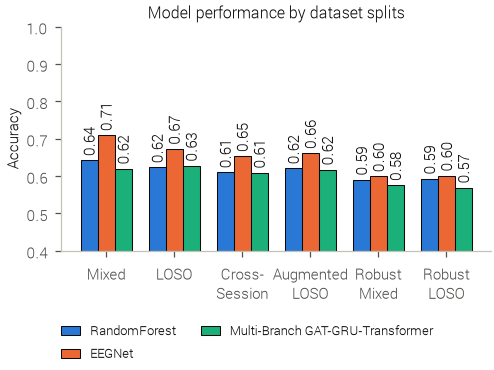

In [3]:
# model comparison - overall
def plot_overall_performance_comparison():
    dataset_names = ['Mixed', 'LOSO', 'Cross-\nSession', 'Augmented\nLOSO', 'Robust\nMixed', 'Robust\nLOSO']
    content = {
        'RandomForest': (
            rf_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in rf_leave_one_out_run.items()]),
            rf_cross_session_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in rf_leave_one_out_augmented_run.items()]),
            rf_robust_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in rf_robust_leave_one_out_run.items()])
        ),
        'EEGNet': (
            eegnet_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in eegnet_leave_one_out_run.items()]),
            eegnet_cross_session_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in eegnet_leave_one_out_augmented_run.items()]),
            eegnet_robust_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in eegnet_robust_leave_one_out_run.items()])
        ),
        'Multi-Branch GAT-GRU-Transformer': (
            transformer_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in transformer_leave_one_out_run.items()]),
            transformer_cross_session_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in transformer_leave_one_out_augmented_run.items()]),
            transformer_robust_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in transformer_robust_leave_one_out_run.items()]),
        )
    }

    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 2.5))

    res = ax.grouped_bar(content, tick_labels=dataset_names, group_spacing=1, edgecolor=INK_PRIMARY, colors=CAT_COLORS[0:3])
    for container in res.bar_containers:
        ax.bar_label(container, padding=2, fmt="%.2f", rotation=90)  # vertical: 18 bars share one column

    # Add some text for labels, title, etc.
    ax.set_ylabel('Accuracy')
    ax.set_title('Model performance by dataset splits')
    fig.legend(frameon=False, loc='outside lower center', ncols=2)
    ax.set_ylim(0.4, 1.)
    clean_axes(ax)
    savefig(fig, 'model_perf_by_dataset_split.pdf')

plot_overall_performance_comparison()

wrote out_thesis\figs\pub\model_perf_by_distractors.pdf


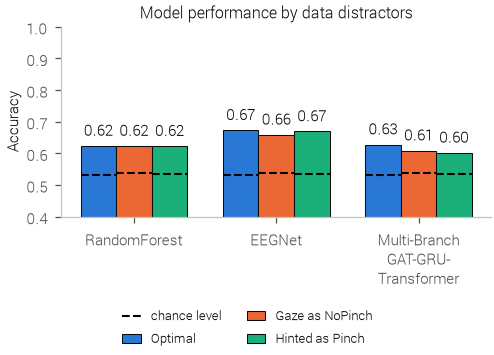

In [4]:
# model comparison - impact of hinted, ignored, and gaze events in leave-one-out

def get_accs_by_type(type: str):
    return (
        get_acc(globals()[f'rf_{type}']),
        get_acc(globals()[f'eegnet_{type}']),
        get_acc(globals()[f'transformer_{type}'])
    )

def get_baseline_by_type(type: str):
    return (
        get_baseline(globals()[f'rf_{type}']),
        get_baseline(globals()[f'eegnet_{type}']),
        get_baseline(globals()[f'transformer_{type}'])
    )

def get_acc(data: dict):
    if 'result' in data:
        return data['result']['test_accuracy']
    else:
        return np.average([v['result']['test_accuracy'] for k, v in data.items()])

def get_baseline(data: dict):
    """
    Estimate the baseline accuracy using the majority-class baseline.
    """
    if 'result' in data:
        cm = np.asarray(data['result']["confusion_matrix"])
        true_class_counts = cm.sum(axis=1)  # rows = true labels
        total = true_class_counts.sum()
        return true_class_counts.max() / total
    else:
        true_class_counts = 0
        total = 0
        for s in data.keys():
            cm = np.asarray(data[s]['result']["confusion_matrix"])
            true_class_counts += cm.sum(axis=1).max()  # rows = true labels
            total += cm.sum(axis=1).sum()

        return true_class_counts / total


def plot_overall_performance_comparison():
    dataset_names = ['RandomForest', 'EEGNet', 'Multi-Branch\nGAT-GRU-\nTransformer']
    content = {
        'Optimal': get_accs_by_type('leave_one_out_run'),
        'Gaze as NoPinch': get_accs_by_type('leave_one_out_gaze_run'),
        # 'Ignored as Pinch': get_accs_by_type('leave_one_out_ignored_run'),
        'Hinted as Pinch': get_accs_by_type('leave_one_out_hinted_run'),
        # 'Random finger movements\nas NoPinch': get_accs_by_type('leave_one_out_run'),
    }
    chance = {
        'Optimal': get_baseline_by_type('leave_one_out_run'),
        'Gaze as NoPinch': get_baseline_by_type('leave_one_out_gaze_run'),
        # 'Ignored as Pinch': get_baseline_by_type('leave_one_out_ignored_run'),
        'Hinted as Pinch': get_baseline_by_type('leave_one_out_hinted_run'),
        # 'Random finger movements\nas NoPinch': (0.5, 0.5, 0.5),
    }

    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 2.4))

    res = ax.grouped_bar(content, tick_labels=dataset_names, group_spacing=1, edgecolor=INK_PRIMARY, colors=CAT_COLORS[0:3])

    # plot a per-bar chance level (determined by the ratio of the dominant class)
    first_line = True
    for label, container in zip(content, res.bar_containers):
        for bar, c in zip(container.patches, chance[label]):
            ax.hlines(c, bar.get_x(), bar.get_x() + bar.get_width(),
                      colors='black', linestyles='--', linewidth=1.0,
                      label='chance level' if first_line else None)
            first_line = False

    for container in res.bar_containers:
        ax.bar_label(container, padding=3, fmt="%.2f")

    ax.set_ylabel('Accuracy')
    ax.set_title('Model performance by data distractors')
    fig.legend(frameon=False, loc='outside lower center', ncols=2)
    ax.set_ylim(0.4, 1.)
    clean_axes(ax)
    savefig(fig, 'model_perf_by_distractors.pdf')

    # Add some text for labels, title, etc.

plot_overall_performance_comparison()

In [5]:
# model comparison - impact of feedback

wrote out_thesis\figs\pub\subject_comparison.pdf


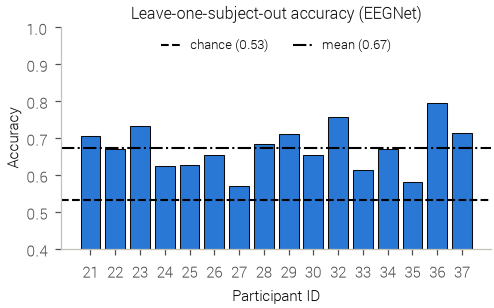

In [6]:
# showing the differences between subjects
def plot_subject_comparison():
    results = eegnet_leave_one_out_run
    accuracies = [result['result']['test_accuracy'] for result in results.values()]
    chance = get_baseline_by_type('leave_one_out_run')
    fig, ax = plt.subplots(layout='constrained', figsize=(COL_W, 2.1))
    ax.bar([subject_id(s) for s in results], accuracies, edgecolor=INK_PRIMARY, color=CAT_COLORS[0])
    ax.set_xlabel("Participant ID")
    ax.set_ylabel("Accuracy")
    ax.set_title("Leave-one-subject-out accuracy (EEGNet)")
    ax.set_ylim(0.4, 1.)
    ax.axhline(chance[1], color="black", linestyle="--", linewidth=1.0,
        label=f"chance ({chance[1]:.2f})",
    )
    ax.axhline(np.mean(accuracies), color="black", linestyle="-.", linewidth=1.0,
        label=f"mean ({np.mean(accuracies):.2f})",
    )
    ax.legend(frameon=False, loc='upper center', ncols=2)
    clean_axes(plt.gca())
    savefig(fig, 'subject_comparison.pdf')


plot_subject_comparison()

## Reporting all results currently available

In [7]:
import os


def compute_metrics(data):
    cm = np.array(data["confusion_matrix"], dtype=float)
    classes = list(data["classes"])
    pos_idx = classes.index('PinchLog')

    total = cm.sum()
    correct = np.trace(cm)
    accuracy = correct / total

    tp = cm[pos_idx, pos_idx]
    fp = cm[:, pos_idx].sum() - tp
    fn = cm[pos_idx, :].sum() - tp
    tn = total - tp - fp - fn

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "fpr": fpr,
    }


def mean_of_dicts(dict_list):
    keys = dict_list[0].keys()
    return {
        key: np.mean([d[key] for d in dict_list])
        for key in keys
    }

def report_results(folder_path):
    results = {}
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        if os.path.isfile(file_path):
            name_without_ext = os.path.splitext(filename)[0]
            data = load_cached(name_without_ext)
            # prepare data layout
            if isinstance(data, tuple):
                data = {
                    'result': data[0],
                    'test_metadata': data[1],
                }
            if 'model' in data:
                data = {
                    'result': data
                }
            # compute results
            if 'result' in data:
                results[name_without_ext] = compute_metrics(data['result'])
                pass
            else:
                # compute mean
                vals = []
                for s in data.keys():
                    vals.append(compute_metrics(data[s]['result']))

                results[name_without_ext] = mean_of_dicts(vals)

    return pd.DataFrame.from_dict(results).T


results = report_results('out/results')

In [8]:
results

,accuracy,precision,recall,f1,fpr
eegnet_cross_session_run,0.653150,0.653727,0.621861,0.637396,0.316761
eegnet_cross_subject_run,0.756173,0.723684,0.748299,0.735786,0.237288
eegnet_general_run,0.709130,0.675889,0.756637,0.713987,0.334694
eegnet_leave_one_out_augmented_run,0.672987,0.667869,0.687838,0.665382,0.337683
eegnet_leave_one_out_finger_run,0.673565,0.690265,0.667954,0.663832,0.320383
eegnet_leave_one_out_gaze_run,0.658324,0.646178,0.638807,0.633504,0.319716
eegnet_leave_one_out_hinted_run,0.668905,0.713328,0.671466,0.678123,0.329220
eegnet_leave_one_out_ignored_run,0.661180,0.682146,0.658391,0.654673,0.331713
eegnet_leave_one_out_run,0.672792,0.672943,0.652033,0.653637,0.304332
eegnet_robust_general_run,0.599065,0.618947,0.542435,0.578171,0.342803
